# 04 · Tree models, prediction intervals and a first stopping rule

The Ch 6–7 drills (HOML_exercises/ch06) explored single trees, extrapolation, forests, boosting and quantile intervals. This notebook brings the useful parts into the main repo and moves the project on to **parts 2 and 3 of the objective**:

> How trustworthy is an early-life prediction for a new batch of cells, and can it safely decide when to stop a cycling test?

| Section | Question |
|---|---|
| 1 | Tree models in the results table, and on a new batch (leave-one-batch-out) |
| 2 | Which features matter? Permutation importance on held-out folds, twins permuted together |
| 3 | 80% intervals on the paper's split: coverage, with misses split into **dangerous** (below) and harmless (above) |
| 4 | Do the intervals flag b2c1 and the long-lived batch 3 cells? |
| 5 | **Batch-calibrated conformal**: do intervals built from batch-to-batch errors survive a new batch? |
| 6 | A novelty flag: is this cell unlike anything in training? |
| 7 | **First stopping rule**: cycler time saved vs dangerous misses |

**Which misses are dangerous?** A stopping rule ends a test at cycle 100 and reports the interval. If the cell then dies **before** the lower bound (true life below the interval, like b2c1), the rule promised life the cell didn't have. If it lives **beyond** the upper bound, the rule was pessimistic: wasteful but safe.

**Rules carried over:** log₁₀ life target, % errors in cycles; CV grouped by charge policy; models **chosen by CV**; test sets only scored.

*Reading: Hands-On ML Ch 6 and 7 (done in the drills).*

The leave-one-batch-out cells take a couple of minutes.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import FEATURE_COLUMNS, load_feature_table
from src.evaluate import (BATCHES, evaluate, grouped_cv, pct_error,
                          save_metrics, signed_pct)

FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
METRICS_CSV = ROOT / "results" / "metrics.csv"
SEED = 42
F = FEATURE_COLUMNS

data = load_feature_table(ROOT / "data" / "processed" / "features.csv")
y = np.log10(data["cycle_life"])
train = data[data["split"] == "train"]
X_tr, y_tr, groups_tr = train[F], np.log10(train["cycle_life"]), train["charge_policy"]
cv = grouped_cv(5)
MAE = "neg_mean_absolute_error"
COLS = ["cv_log_mae", "train_pct", "test_pct", "secondary_test_pct", "b1_bias_pct", "b2_bias_pct", "b3_bias_pct"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def lin_pipe(model):
    """Linear models: impute, scale, model (as in notebook 03)."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)


def tree_pipe(model):
    """Tree models: impute, model. No scaler: splits don't care about units (Ch 6)."""
    return make_pipeline(SimpleImputer(strategy="median"), model)


def short(params):
    """{'randomforestregressor__max_features': 0.6} -> {'max_features': 0.6}"""
    return {k.split("__")[1]: (float(np.round(v, 4)) if isinstance(v, float) else v)
            for k, v in params.items()}


# Reference: best linear model from notebook 03 (chosen there by grouped CV)
EN_BEST = lin_pipe(ElasticNet(alpha=10 ** -2.2, l1_ratio=0.7, max_iter=50_000))  # alpha ≈ 0.0063
rows = []
row, en_fit = evaluate("Elastic net", EN_BEST, data, F, note="{'alpha': 0.0063, 'l1_ratio': 0.7}")
rows.append(row)
print(data["split"].value_counts().to_dict())

{'test': 43, 'train': 41, 'secondary_test': 40}


## 1 · Tree models in the results table

The three tree families from the drills, each tuned by grouped CV on the 41 training cells and added to `results/metrics.csv` next to the notebook 03 models. The grids are small: the drills showed CV is flat within noise across most settings.

In [2]:
searches = {
    "Decision tree": (tree_pipe(DecisionTreeRegressor(random_state=SEED)),
                      {"decisiontreeregressor__max_depth": [2, 3, 4, 5, None],
                       "decisiontreeregressor__min_samples_leaf": [1, 3, 5]}),
    "Random forest": (tree_pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
                      {"randomforestregressor__max_features": [1.0, 0.6, 0.3],
                       "randomforestregressor__min_samples_leaf": [1, 2, 4]}),
    "Gradient boosting": (tree_pipe(GradientBoostingRegressor(subsample=0.8, random_state=SEED)),
                          {"gradientboostingregressor__learning_rate": [0.03, 0.1],
                           "gradientboostingregressor__n_estimators": [50, 100, 300],
                           "gradientboostingregressor__max_depth": [1, 2, 3]}),
}
tuned = {}
for name, (model, grid) in searches.items():
    s = GridSearchCV(model, grid, cv=cv, scoring=MAE).fit(X_tr, y_tr, groups=groups_tr)
    tuned[name] = s.best_estimator_
    row, _ = evaluate(name, s.best_estimator_, data, F, note=str(short(s.best_params_)))
    rows.append(row)
    print(f"{name:18s} {short(s.best_params_)}  CV log-MAE {-s.best_score_:.4f}")

table = save_metrics(rows, METRICS_CSV)
table.loc[[r["model"] for r in rows], COLS].round(3)

Decision tree      {'max_depth': 4, 'min_samples_leaf': 1}  CV log-MAE 0.0712
Random forest      {'max_features': 0.6, 'min_samples_leaf': 1}  CV log-MAE 0.0636
Gradient boosting  {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}  CV log-MAE 0.0561


,cv_log_mae,train_pct,test_pct,secondary_test_pct,b1_bias_pct,b2_bias_pct,b3_bias_pct
model,,,,,,,
Elastic net,0.040,7.246,11.569,12.486,-3.214,8.224,-7.440
Decision tree,0.071,4.498,16.445,18.451,-8.599,10.988,-8.887
Random forest,0.064,4.651,13.373,12.956,-7.390,12.558,-9.544
Gradient boosting,0.056,1.185,11.164,11.643,-3.717,8.136,-8.554


In [3]:
# Leave-one-batch-out for each family (hyperparameters re-tuned inside the two training batches)
EN_GRID = {"elasticnet__alpha": np.logspace(-4, 0, 21), "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}
families = {"Elastic net": (lin_pipe(ElasticNet(max_iter=50_000)), EN_GRID),
            "Random forest": searches["Random forest"],
            "Gradient boosting": searches["Gradient boosting"]}
lobo = []
for held_out in BATCHES:
    tr_m = data["batch"] != held_out
    for name, (model, grid) in families.items():
        s = GridSearchCV(model, grid, cv=cv, scoring=MAE)
        s.fit(data.loc[tr_m, F], y[tr_m], groups=data.loc[tr_m, "charge_policy"])
        p = s.predict(data.loc[~tr_m, F])
        lobo.append({"held_out": held_out, "model": name,
                     "abs_err_pct": pct_error(y[~tr_m], p).mean(),
                     "bias_pct": signed_pct(y[~tr_m], p).mean()})
lobo = pd.DataFrame(lobo)
lobo.pivot(index="held_out", columns="model", values=["abs_err_pct", "bias_pct"]).round(1)

abs_err_pct                                    bias_pct  \
model    Elastic net Gradient boosting Random forest Elastic net   
held_out                                                           
b1              13.7              23.8          23.2       -11.2   
b2              24.1              37.8          41.6        23.7   
b3              11.3              12.1          12.5        -5.5   

                                          
model    Gradient boosting Random forest  
held_out                                  
b1                   -23.8         -22.3  
b2                    37.8          41.6  
b3                    -5.6          -7.8

The main repo reproduces the drills: the elastic net is best by CV (0.040 vs boosting 0.056, forest 0.064, tree 0.071). Boosting’s lower test error (11.2 vs 11.6%) is within noise and isn’t grounds to choose it; its 1.2% train error shows heavier overfitting. On the paper’s split, batch biases are similar across models (b3 −7 to −10%). In leave-one-batch-out, the trees are much worse: b1 −22 to −24% (EN −11%) and b2 +38 to +42% (EN +24%); b3 is similar (−6 to −8%). Reason: tree predictions are averages of training lives, so they can’t go below the shortest training cell. Trained on b1 + b3, that floor is 534 cycles, but 40 of 43 b2 cells live shorter (median 481, min 148). So trees must over-predict nearly all of b2. The elastic net has no floor and follows the trend below the training range, though it still over-predicts b2 (+24%) because of domain shift. Trees are the less safe choice for a new batch with shorter lives than training.

## 2 · Which features matter? Permutation importance done properly

The drills found two traps:
- **impurity importance** ranked a random-noise column 10th of 13, because it counts overfitted splits as importance;
- permuting **one twin** at a time under-counts the pair, because the other twin still carries the information.

So here: permutation importance on **held-out grouped CV folds** (never the cells the model was fitted on), with each **twin pair shuffled together**, and a **random-noise column** as a control. Anything not clearly above the noise bar is indistinguishable from nothing. Done for the elastic net and the best tree model, to see whether they rely on the same information.

,Elastic net,Gradient boosting
ΔQ twins (var + min),0.0713,0.0491
ir_min,0.0219,0.0132
charge_time_2to6,0.0127,0.0090
capacity twins (qd_cycle2 + fade_intercept),0.0090,0.0042
noise (control),0.0005,0.0006
log_abs_kurt_dq,0.0000,0.0006
fade_slope,0.0000,0.0012
temp_max,-0.0001,0.0008
log_abs_skew_dq,-0.0001,0.0023
ir_change_2to100,-0.0005,0.0033


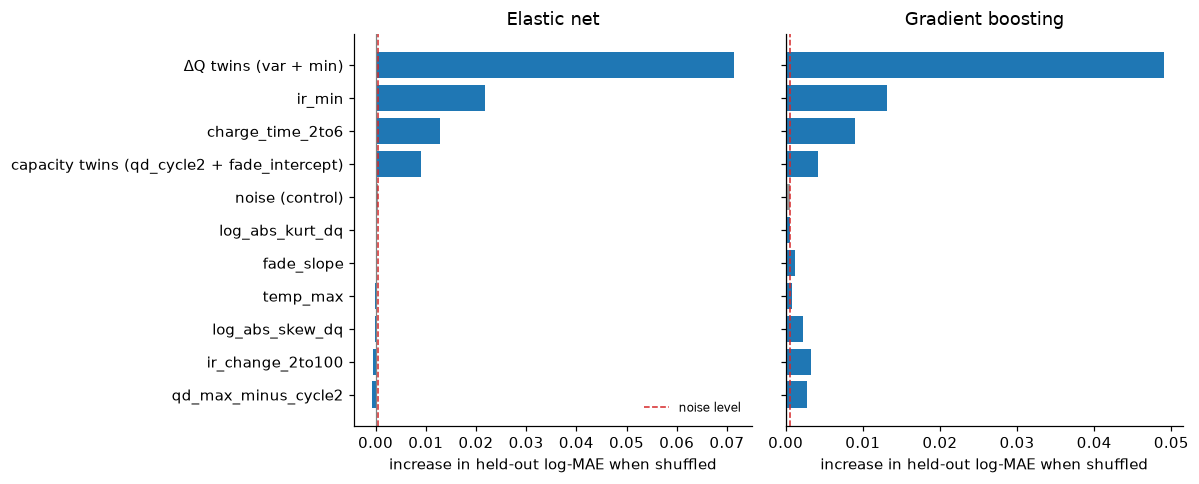

In [4]:
rng = np.random.default_rng(SEED)
X_noise = X_tr.copy()
X_noise["noise (control)"] = rng.normal(size=len(X_noise))

TWINS = {"ΔQ twins (var + min)": ["log_var_dq", "log_abs_min_dq"],
         "capacity twins (qd_cycle2 + fade_intercept)": ["qd_cycle2", "fade_intercept"]}
in_twins = {c for cols in TWINS.values() for c in cols}
PERM_GROUPS = {**TWINS, **{f: [f] for f in F if f not in in_twins}, "noise (control)": ["noise (control)"]}


def heldout_perm_importance(model, X, y_, groups, n_repeats=20):
    """Mean increase in held-out log-MAE when a group of columns is shuffled together."""
    gen = np.random.default_rng(SEED)
    out = {g: [] for g in PERM_GROUPS}
    for tr_i, va_i in cv.split(X, y_, groups):
        m = clone(model).fit(X.iloc[tr_i], y_.iloc[tr_i])
        Xv, yv = X.iloc[va_i], y_.iloc[va_i].to_numpy()
        base = np.abs(m.predict(Xv) - yv).mean()
        for g, cols in PERM_GROUPS.items():
            for _ in range(n_repeats):
                Xp = Xv.copy()
                Xp[cols] = Xv[cols].to_numpy()[gen.permutation(len(Xv))]
                out[g].append(np.abs(m.predict(Xp) - yv).mean() - base)
    return pd.Series({g: np.mean(v) for g, v in out.items()})


best_tree_name = min(["Random forest", "Gradient boosting"],
                     key=lambda n: table.loc[n, "cv_log_mae"])
imp = pd.DataFrame({
    "Elastic net": heldout_perm_importance(EN_BEST, X_noise, y_tr, groups_tr),
    best_tree_name: heldout_perm_importance(clone(tuned[best_tree_name]), X_noise, y_tr, groups_tr),
}).sort_values("Elastic net")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col in zip(axes, imp.columns):
    ax.barh(imp.index, imp[col], color=["0.6" if i == "noise (control)" else "C0" for i in imp.index])
    ax.axvline(max(imp.loc["noise (control)", col], 0), color="C3", ls="--", lw=1, label="noise level")
    ax.axvline(0, color="0.5", lw=0.8)
    ax.set(title=col, xlabel="increase in held-out log-MAE when shuffled")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_permutation_importance.png", dpi=200)
imp.iloc[::-1].round(4)

Permutation importance on held-out grouped folds, twins shuffled together, with a random-noise control (≈0.0005). Clearly above noise for both models, in the same order: ΔQ twins (EN 0.071, boosting 0.049), ir_min (0.022 / 0.013), charge_time_2to6 (0.013 / 0.009), capacity twins (0.009 / 0.004). The linear and tree models rely on the same information. Below the top four: EN scores are ≈0 or slightly negative (unused; a negative score just means shuffling changed the error by chance). Boosting gives a few small positive scores (ir_change 0.003, qd_max_minus 0.003, skew 0.002), but they’re ~5% of the ΔQ twins and within the noise of a single control on ~8-cell folds. Not trustworthy, and possibly boosting fitting noise. Compared with the drills (one-at-a-time, RF): log_var_dq 0.014 + log_abs_min_dq 0.013 = 0.027 separately vs 0.036 together. Shuffling one twin under-counts the pair. Grouped, the ΔQ twins are ~3× the next feature, and the capacity twins rise to 4th (outside the top five one-at-a-time).

## 3 · 80% prediction intervals on the paper's split

| Method | How | Width |
|---|---|---|
| **EN + policy conformal** | Elastic net. Half-width = 80th percentile of its out-of-fold errors under **policy-grouped** CV on the training cells | Same for every cell |
| **EN + batch conformal** | Same, but the out-of-fold errors come from **leave-one-batch-out** inside the training cells: train on one batch, predict the other. So the errors include batch shift | Same for every cell |
| **RF tree spread** | 10th–90th percentile of the forest's individual tree predictions | Per cell |
| **Quantile boosting** | Two extra boosting models fitted to the 10th and 90th percentiles (`loss="quantile"`) | Per cell |

The quantile models are fitted separately from the main one, so they can cross it; the code clamps the interval to contain the prediction. Watch for intervals with one side of zero width.

Checks per split:
- **coverage** (target 80%), split into **below** (dangerous: cell died sooner than the lower bound) and **above** (harmless). A well-calibrated 80% interval misses about 10% each side;
- **half-width** (± % of the prediction);
- **ρ**, the rank correlation between width and actual error (does it widen where it's wrong?).

In [5]:
LEVEL = 0.80
LO, HI = (1 - LEVEL) / 2, 1 - (1 - LEVEL) / 2   # 0.1, 0.9
RF_BEST, GB_BEST = tuned["Random forest"], tuned["Gradient boosting"]


def conformal_halfwidth(model, X, y_, groups, splitter, level=LEVEL):
    """Conformal half-width: the level-quantile of out-of-fold absolute errors."""
    oof = cross_val_predict(clone(model), X, y_, groups=groups, cv=splitter)
    r = np.sort(np.abs(np.asarray(y_) - oof))
    k = int(np.ceil((len(r) + 1) * level))
    return r[min(k, len(r)) - 1]


def intervals(train_df, pred_df):
    """80% intervals (log10 life) for every cell in pred_df, from models fitted on train_df only."""
    Xt, yt = train_df[F], np.log10(train_df["cycle_life"])
    Xp = pred_df[F]
    out = {}

    mid = clone(EN_BEST).fit(Xt, yt).predict(Xp)
    q_pol = conformal_halfwidth(EN_BEST, Xt, yt, train_df["charge_policy"], cv)
    out["EN + policy conformal"] = pd.DataFrame({"lo": mid - q_pol, "mid": mid, "hi": mid + q_pol}, index=pred_df.index)
    q_bat = conformal_halfwidth(EN_BEST, Xt, yt, train_df["batch"], LeaveOneGroupOut())
    out["EN + batch conformal"] = pd.DataFrame({"lo": mid - q_bat, "mid": mid, "hi": mid + q_bat}, index=pred_df.index)

    rf = clone(RF_BEST).fit(Xt, yt)
    per_tree = np.stack([t.predict(rf[:-1].transform(Xp)) for t in rf[-1].estimators_])
    out["RF tree spread"] = pd.DataFrame({"lo": np.quantile(per_tree, LO, axis=0), "mid": per_tree.mean(axis=0),
                                          "hi": np.quantile(per_tree, HI, axis=0)}, index=pred_df.index)

    mid = clone(GB_BEST).fit(Xt, yt).predict(Xp)
    q = {name: clone(GB_BEST).set_params(gradientboostingregressor__loss="quantile",
                                         gradientboostingregressor__alpha=a).fit(Xt, yt).predict(Xp)
         for name, a in [("lo", LO), ("hi", HI)]}
    out["Quantile boosting"] = pd.DataFrame({"lo": np.minimum(q["lo"], mid), "mid": mid,
                                             "hi": np.maximum(q["hi"], mid)}, index=pred_df.index)
    return out


def half_width_pct(iv):
    return 100 * (10 ** iv["hi"] - 10 ** iv["lo"]) / (2 * 10 ** iv["mid"])


def score_intervals(ivs, cells):
    """Coverage (with misses below / above), mean half-width, error and width-error correlation."""
    res = []
    for method, iv in ivs.items():
        iv = iv.loc[cells]
        t = y.loc[cells]
        hw, err = half_width_pct(iv), pct_error(t, iv["mid"])
        res.append({"method": method, "n": len(cells),
                    "coverage_pct": 100 * ((t >= iv["lo"]) & (t <= iv["hi"])).mean(),
                    "below_pct (dangerous)": 100 * (t < iv["lo"]).mean(),
                    "above_pct": 100 * (t > iv["hi"]).mean(),
                    "half_width_pct": hw.mean(), "abs_err_pct": err.mean(),
                    "width_vs_error_rho": spearmanr(hw, err)[0]})
    return pd.DataFrame(res).set_index("method")


ivs = intervals(train, data[data["split"] != "train"])
summary = []
for split in ["test", "secondary_test"]:
    s = score_intervals(ivs, data.index[data["split"] == split])
    s.insert(0, "split", split)
    summary.append(s)
pd.concat(summary).round(1)

,split,n,coverage_pct,below_pct (dangerous),above_pct,half_width_pct,abs_err_pct,width_vs_error_rho
method,,,,,,,,
EN + policy conformal,test,43,86.0,7.0,7.0,17.1,11.6,-0.1
EN + batch conformal,test,43,97.7,2.3,0.0,41.9,11.6,0.1
RF tree spread,test,43,83.7,4.7,11.6,21.3,13.4,0.4
Quantile boosting,test,43,62.8,16.3,20.9,22.0,11.2,0.3
EN + policy conformal,secondary_test,40,67.5,2.5,30.0,17.1,12.5,0.1
EN + batch conformal,secondary_test,40,97.5,0.0,2.5,41.9,12.5,-0.2
RF tree spread,secondary_test,40,90.0,0.0,10.0,35.0,13.0,0.4
Quantile boosting,secondary_test,40,40.0,0.0,60.0,25.9,11.6,0.3


80% intervals on the paper split. Primary test: policy conformal 86% (±17%) and RF spread 84% (±21%) are both within ~2 cells of 80% (1 cell ≈ 2.3 points); their misses are split roughly evenly below/above. Batch 3: policy conformal falls to 67.5% (~5 cells short), but all misses are above (b3 under-predicted, lives longer), i.e. harmless for a stopping rule. RF spread widens by itself for b3 (±21 → ±35%) and covers 90%, so tree disagreement does respond to the shifted batch. Batch conformal is over-cautious: ~98% on both sets at ±42%, because its widths come from batch-to-batch errors, which include batch shift. On b3 that extra width isn’t needed (policy conformal’s misses were harmless); test on a harder batch in section 5. Quantile boosting is over-confident: 63% / 40% (7 and 16 cells short, well beyond noise), with 16% of primary-test cells below the interval (dangerous); unreliable with 41 training cells. Width–error correlation: RF 0.4, quantile boosting 0.3, conformal ≈0 (constant width by design).

## 4 · Do the intervals flag the hard cells?

From notebook 03: b2c1 (148 cycles, the paper's excluded cell) and the long-lived batch 3 cells the elastic net under-predicted most. A useful interval either **contains** the true life or is **clearly wider than usual** for these cells.

true      lo    pred      hi  \
method                cell                                    
EN + policy conformal b2c1    148.0   277.0   328.0   389.0   
                      b3c38  1935.0   859.0  1018.0  1207.0   
                      b3c7   1836.0  1085.0  1286.0  1525.0   
                      b3c45  1801.0  1101.0  1305.0  1547.0   
                      b3c41   786.0   488.0   578.0   685.0   
                      b3c22  1002.0   637.0   755.0   895.0   
EN + batch conformal  b2c1    148.0   218.0   328.0   494.0   
                      b3c38  1935.0   677.0  1018.0  1531.0   
                      b3c7   1836.0   855.0  1286.0  1934.0   
                      b3c45  1801.0   868.0  1305.0  1962.0   
                      b3c41   786.0   384.0   578.0   869.0   
                      b3c22  1002.0   502.0   755.0  1135.0   
RF tree spread        b2c1    148.0   300.0   400.0   559.0   
                      b3c38  1935.0   709.0   986.0  1434.0   
                      b3c7   1836.0   788.0  1138.0  2160.0   
                      b3c45  1801.0   783.0  1111.0  2160.0   
                      b3c41   786.0   494.0   933.0  2160.0   
                      b3c22  1002.0   693.0   822.0  1074.0   
Quantile boosting     b2c1    148.0   320.0   341.0   640.0   
                      b3c38  1935.0   485.0  1154.0  1193.0   
                      b3c7   1836.0   488.0  1431.0  1431.0   
                      b3c45  1801.0   488.0  1383.0  1383.0   
                      b3c41   786.0   462.0   795.0   990.0   
                      b3c22  1002.0   485.0   785.0   820.0   

                                          miss  half_width_pct  typical_pct  
method                cell                                                   
EN + policy conformal b2c1   below (dangerous)            17.0         17.0  
                      b3c38              above            17.0         17.0  
                      b3c7               above            17.0         17.0  
                      b3c45              above            17.0         17.0  
                      b3c41              above            17.0         17.0  
                      b3c22              above            17.0         17.0  
EN + batch conformal  b2c1   below (dangerous)            42.0         42.0  
                      b3c38              above            42.0         42.0  
                      b3c7              inside            42.0         42.0  
                      b3c45             inside            42.0         42.0  
                      b3c41             inside            42.0         42.0  
                      b3c22             inside            42.0         42.0  
RF tree spread        b2c1   below (dangerous)            32.0         22.0  
                      b3c38              above            37.0         22.0  
                      b3c7              inside            60.0         22.0  
                      b3c45             inside            62.0         22.0  
                      b3c41             inside            89.0         22.0  
                      b3c22             inside            23.0         22.0  
Quantile boosting     b2c1   below (dangerous)            47.0         22.0  
                      b3c38              above            31.0         22.0  
                      b3c7               above            33.0         22.0  
                      b3c45              above            32.0         22.0  
                      b3c41             inside            33.0         22.0  
                      b3c22              above            21.0         22.0

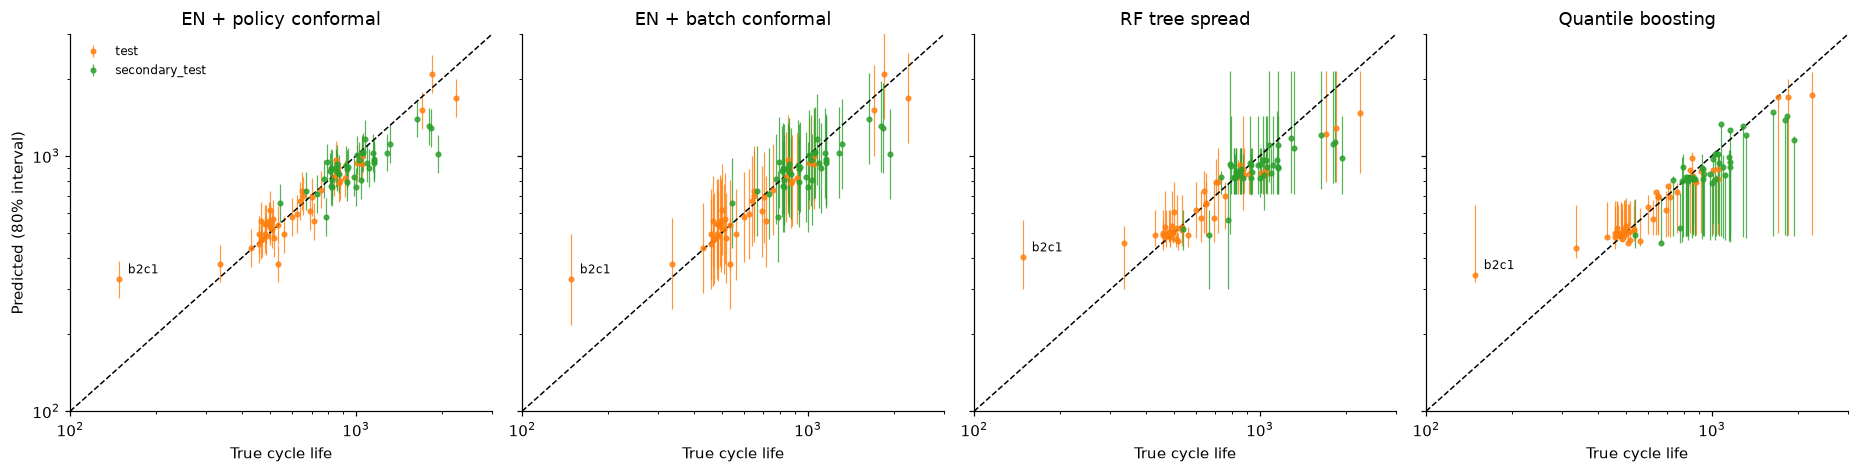

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharex=True, sharey=True)
lims = [100, 3000]
for ax, (method, iv) in zip(axes, ivs.items()):
    for split, colour in [("test", "C1"), ("secondary_test", "C2")]:
        idx = data.index[data["split"] == split]
        mid, lo, hi = 10 ** iv.loc[idx, "mid"], 10 ** iv.loc[idx, "lo"], 10 ** iv.loc[idx, "hi"]
        ax.errorbar(data.loc[idx, "cycle_life"], mid, yerr=[mid - lo, hi - mid], fmt="o", ms=3,
                    color=colour, elinewidth=0.8, alpha=0.8, label=split)
    ax.plot(lims, lims, "k--", lw=1)
    ax.annotate("b2c1", (data.loc["b2c1", "cycle_life"], 10 ** iv.loc["b2c1", "mid"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
    ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, title=method, xlabel="True cycle life")
axes[0].set_ylabel("Predicted (80% interval)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_intervals.png", dpi=200)

hard = [c for c in ["b2c1", "b3c38", "b3c7", "b3c45", "b3c41", "b3c22"] if c in data.index]
rows_hard = []
for method, iv in ivs.items():
    typical = half_width_pct(iv).median()
    for c in hard:
        lo, mid, hi = 10 ** iv.loc[c, ["lo", "mid", "hi"]]
        true = data.loc[c, "cycle_life"]
        rows_hard.append({"method": method, "cell": c, "true": true, "lo": lo, "pred": mid, "hi": hi,
                          "miss": "below (dangerous)" if true < lo else ("above" if true > hi else "inside"),
                          "half_width_pct": 100 * (hi - lo) / (2 * mid), "typical_pct": typical})
pd.DataFrame(rows_hard).set_index(["method", "cell"]).round(0)

Section 4 notes: No method contains b2c1 (148 cycles); all miss below, the dangerous direction. Intervals: policy conformal 277–389, batch conformal 218–494 (closest, but only because it is wide for every cell), RF 300–559, quantile boosting 320–640. The tree methods give b2c1 a wider-than-typical interval (RF 32% vs 22%; QB 47% vs 22%), so they partly sense it’s unusual, but the interval is in the wrong place. Conformal widths are constant, so they can’t flag individual cells. Tree methods can never reach 148 cycles: predictions and tree percentiles can’t go below the shortest training life (300 cycles); RF’s lower bound sits exactly at 300. Long-lived b3 cells: every miss is above (harmless for a stopping rule). Policy conformal misses all 5; batch conformal and RF contain 4 of 5. RF widens strongly for these cells (60–89%) but its upper bounds cap at 2160, the training maximum. Quantile boosting misses 4 of 5 above, and three intervals have zero width on the upper side (crossed quantiles clamped).

## 5 · Extension: intervals on a new batch

Section 3 used the paper's split, where batch 3 is new but batches 1 and 2 share training. Here each batch is held out in turn and **everything** (models, conformal widths) is built from the other two batches only. For batch conformal, that means the width comes from training on one remaining batch and predicting the other.

If batch-to-batch errors are a fair guide to the next batch, batch conformal should cover close to 80% on every held-out batch.

In [7]:
cov, lobo_ivs = [], {}
for held_out in BATCHES:
    tr_df, pr_df = data[data["batch"] != held_out], data[data["batch"] == held_out]
    lobo_ivs[held_out] = intervals(tr_df, pr_df)
    s = score_intervals(lobo_ivs[held_out], pr_df.index)
    s.insert(0, "held_out", held_out)
    cov.append(s.reset_index())
cov = pd.concat(cov, ignore_index=True)
cov.pivot(index="held_out", columns="method",
          values=["coverage_pct", "below_pct (dangerous)", "half_width_pct"]).round(1)

coverage_pct                                          \
method   EN + batch conformal EN + policy conformal Quantile boosting   
held_out                                                                
b1                      100.0                  61.0              39.0   
b2                       37.2                  30.2               0.0   
b3                       97.5                  67.5              50.0   

                        below_pct (dangerous)                        \
method   RF tree spread  EN + batch conformal EN + policy conformal   
held_out                                                              
b1                 61.0                   0.0                   4.9   
b2                  0.0                  62.8                  69.8   
b3                 85.0                   0.0                   5.0   

                                                half_width_pct  \
method   Quantile boosting RF tree spread EN + batch conformal   
held_out                                                         
b1                     0.0            0.0                 63.0   
b2                   100.0          100.0                 14.9   
b3                     0.0            0.0                 51.7   

                                                                 
method   EN + policy conformal Quantile boosting RF tree spread  
held_out                                                         
b1                        15.8              17.8           23.0  
b2                        13.5              23.8           11.4  
b3                        14.5              27.0           29.0

Width = interval half-width as ± % of the prediction (±15% on 1,000 cycles ≈ 850–1,150); wider is safer but less useful. Leave-one-batch-out coverage: batch conformal holds best on b1 (100%) and b3 (97.5%), but only via very wide intervals (±63%, ±52%). b2 breaks every method, with misses below (dangerous): batch conformal 37% coverage (63% below), policy conformal 30% (70% below), RF and quantile boosting 0% (100% below, the 534-cycle tree floor). This matches the leave-one-batch-out over-prediction of b2 (EN +24%, trees +38–42%). b1 and b3 misses are above (under-predicted, harmless). Why batch conformal is fragile: its width comes from a single comparison between the two training batches. With b2 held out, that’s b1 ↔ b3, which are similar, so ±15%, far too narrow for b2. With b2 in training, it’s ±52–63%, over-wide. The width reflects how different the two training batches happen to be, not batch shift in general; one comparison can’t estimate the batch-to-batch spread. Calibrating for new batches needs many past batches or some cells from the new batch (k-shot, notebook 03).

## 6 · A novelty flag: is this cell unlike the training cells?

Intervals are learned from training cells, so they can't be trusted for a cell far outside them. A simple guard: express each feature in **training standard deviations** (z-scores) and flag a cell if **any** feature is more than 3σ from the training mean. A flagged cell would not be stopped early, whatever its interval says.

(Week 2's outlier review used the same idea: b2c1's fade slope and kurtosis were beyond 4σ.)

In [8]:
NOVEL_Z = 3.0


def novelty(train_df, pred_df):
    """Largest |z| over the 12 features (training mean/std), and which feature it comes from."""
    mu, sd, med = train_df[F].mean(), train_df[F].std(), train_df[F].median()
    z = ((pred_df[F].fillna(med) - mu) / sd).abs()
    return pd.DataFrame({"max_abs_z": z.max(axis=1), "feature": z.idxmax(axis=1)})


nov = novelty(train, data)
nov["flagged"] = nov["max_abs_z"] > NOVEL_Z
nov["split"], nov["batch"] = data["split"], data["batch"]
nov["EN_err_pct"] = pct_error(y, en_fit.predict(data[F]))

print(nov[nov["split"] != "train"].groupby("split").agg(
    n=("flagged", "size"), flagged=("flagged", "sum"),
    err_flagged=("EN_err_pct", lambda e: e[nov.loc[e.index, "flagged"]].mean()),
    err_not_flagged=("EN_err_pct", lambda e: e[~nov.loc[e.index, "flagged"]].mean())).round(1))
nov[(nov["split"] != "train") & nov["flagged"]].sort_values("max_abs_z", ascending=False).round(1)

                 n  flagged  err_flagged  err_not_flagged
split                                                    
secondary_test  40       10         13.0             12.3
test            43        7         33.4              7.3


,max_abs_z,feature,flagged,split,batch,EN_err_pct
cell,,,,,,
b2c1,14.3,fade_slope,True,test,b2,121.8
b1c2,13.6,log_abs_kurt_dq,True,test,b1,24.7
b1c18,12.5,ir_change_2to100,True,test,b1,12.3
b3c28,5.3,ir_min,True,secondary_test,b3,21.0
b2c36,5.1,ir_min,True,test,b2,29.2
b3c6,4.7,ir_min,True,secondary_test,b3,9.0
b3c17,4.5,log_abs_kurt_dq,True,secondary_test,b3,15.3
b3c21,4.1,ir_min,True,secondary_test,b3,5.0
b1c0,4.0,log_abs_min_dq,True,test,b1,13.0


A novelty flag (any feature > 3σ from the training mean) catches the genuinely odd primary-test cells: b2c1 (fade_slope 14σ), b1c2 (kurtosis 13.6σ, longest-lived cell) and b1c18 (ir_change 12.5σ, the known IR flatline data error, caught without being told). Flagged primary-test cells have much higher error (33.4% vs 7.3%; ~19% excluding b2c1). On batch 3 it flags 10 of 40, via ir_min (3), fade_intercept (4), kurtosis (2) and temp_max (1). These are mostly the week 2 batch shift (ir_min −2.2σ, fade_intercept −1.4σ on average), not odd cells, and their error is no higher (13.0 vs 12.3%). A flag that fires on much of a new batch would block most early stops for the wrong reason. Raising the threshold (e.g. 5σ) would keep the extreme cells but is dataset-specific tuning. Better: separate a batch-level check (has the lot’s mean shifted? → recalibrate with ~10 cells, k-shot) from a cell-level check (z-scores relative to the cell’s own batch). Waiting more cycles before deciding is another dial (fewer cycles saved; doesn’t remove a batch offset).

## 7 · A first stopping rule

At cycle 100, for each cell:

> **Stop the test** if the cell is **not** flagged as novel **and** its 80% interval half-width is at most *W*. Otherwise keep cycling to end of life.

For each method and *W*, count:
- **stopped %**: cells whose test ends at cycle 100;
- **cycles saved %**: cycler time not spent, (true life − 100) summed over stopped cells, as a % of the total for all cells;
- **dangerous**: stopped cells that died **below** the interval's lower bound;
- **harmless misses**: stopped cells that lived beyond the upper bound.

Evaluated two ways: the paper's split (test + secondary) and leave-one-batch-out (every cell predicted by models that never saw its batch). The second is the honest "new cell lot" case.

The two conformal methods give every cell the same width, so for them *W* is all-or-nothing and only the novelty flag selects cells.

In [9]:
W_OPTIONS = [15, 20, 30, np.inf]


def stop_table(ivs, flags):
    """Apply the rule to every cell in ivs: stop if not flagged and half-width <= W."""
    cells = flags.index
    life, t = data.loc[cells, "cycle_life"], y.loc[cells]
    total = (life - 100).sum()
    res = []
    for method, iv in ivs.items():
        iv = iv.loc[cells]
        hw = half_width_pct(iv)
        for W in W_OPTIONS:
            stop = (~flags) & (hw <= W)
            danger = stop & (t < iv["lo"])
            names = list(danger[danger].index)
            res.append({"method": method, "W_pct": W, "stopped_pct": 100 * stop.mean(),
                        "cycles_saved_pct": 100 * (life[stop] - 100).sum() / total,
                        "dangerous": len(names), "harmless_misses": int((stop & (t > iv["hi"])).sum()),
                        "dangerous_cells": ", ".join(names) if len(names) <= 6 else
                        ", ".join(f"{b}: {n}" for b, n in pd.Series([c[:2] for c in names]).value_counts().items())})
    return pd.DataFrame(res).set_index(["method", "W_pct"])


# (a) paper split: intervals (section 3) and novelty (section 6) from the 41 training cells
cells_eval = data.index[data["split"] != "train"]
paper = stop_table(ivs, nov.loc[cells_eval, "flagged"])

# (b) leave-one-batch-out: join the per-batch intervals from section 5, novelty from the other two batches
ivs_lobo = {m: pd.concat([lobo_ivs[b][m] for b in BATCHES]) for m in ivs}
flags_lobo = pd.concat([novelty(data[data["batch"] != b], data[data["batch"] == b])["max_abs_z"] > NOVEL_Z
                        for b in BATCHES])
lobo_stop = stop_table(ivs_lobo, flags_lobo)

print("(a) Paper split, test + secondary (83 cells):")
print(paper.round(1).to_string())
print("\n(b) Leave-one-batch-out, all 124 cells, each predicted by models that never saw its batch:")
lobo_stop.round(1)

(a) Paper split, test + secondary (83 cells):
                             stopped_pct  cycles_saved_pct  dangerous  harmless_misses                         dangerous_cells
method                W_pct                                                                                                   
EN + policy conformal 15.0           0.0               0.0          0                0                                        
                      20.0          79.5              76.8          2               10                            b2c20, b2c42
                      30.0          79.5              76.8          2               10                            b2c20, b2c42
                      inf           79.5              76.8          2               10                            b2c20, b2c42
EN + batch conformal  15.0           0.0               0.0          0                0                                        
                      20.0           0.0               0.0       

stopped_pct  cycles_saved_pct  dangerous  \
method                W_pct                                             
EN + policy conformal 15.0          52.4              51.2         27   
                      20.0          62.1              59.9         27   
                      30.0          62.1              59.9         27   
                      inf           62.1              59.9         27   
EN + batch conformal  15.0          26.6              14.8         25   
                      20.0          26.6              14.8         25   
                      30.0          26.6              14.8         25   
                      inf           62.1              59.9         25   
RF tree spread        15.0          30.6              18.8         30   
                      20.0          38.7              26.9         33   
                      30.0          51.6              42.7         33   
                      inf           62.1              59.9         33   
Quantile boosting     15.0          11.3               8.7          8   
                      20.0          20.2              14.8         16   
                      30.0          52.4              45.5         29   
                      inf           62.1              59.9         33   

                             harmless_misses dangerous_cells  
method                W_pct                                   
EN + policy conformal 15.0                11   b2: 26, b3: 1  
                      20.0                15   b2: 26, b3: 1  
                      30.0                15   b2: 26, b3: 1  
                      inf                 15   b2: 26, b3: 1  
EN + batch conformal  15.0                 0          b2: 25  
                      20.0                 0          b2: 25  
                      30.0                 0          b2: 25  
                      inf                  1          b2: 25  
RF tree spread        15.0                 6          b2: 30  
                      20.0                 6          b2: 33  
                      30.0                10          b2: 33  
                      inf                 10          b2: 33  
Quantile boosting     15.0                 4           b2: 8  
                      20.0                 7          b2: 16  
                      30.0                17          b2: 29  
                      inf                 23          b2: 33

Rule: at cycle 100, keep cycling if the cell is flagged novel (> 3σ); otherwise stop the test if the 80% half-width ≤ W and report the interval. Lower W = stricter = fewer stops: fewer dangerous stops but fewer cycles saved (e.g. RF spread: W15 7% saved / 0 dangerous; W30 49% / 1; ∞ 77% / 1). At W = ∞ all methods stop the same unflagged cells (76.8% saved) and differ only in whether the lower bound was wrong. Paper split: best is batch conformal at W = ∞, 76.8% saved with 0 dangerous; policy conformal 76.8% / 2 dangerous (b2c20, b2c42); quantile boosting worst (5–6). b2c1 is never a dangerous stop because the novelty flag kept it running. Leave-one-batch-out: 25–33 dangerous stops (~20–27% of cells) for any useful saving, almost all b2. Batch conformal at W ≤ 30 stops only b2 cells (the only narrow intervals) and all 25 of its dangerous stops are b2: the width gate selects exactly the batch the intervals are wrong about. A new lot needs the rule to be stricter, not looser. Proposed lab rule: (1) for a new lot, run ~10 cells to end of life with no early stops, recalibrate (k-shot) and check the batch-level shift; (2) then stop unflagged cells at cycle 100 and report the batch-conformal interval. Expected for a lot like training: ~77% cycler time saved, ≤ 2.4% dangerous; without recalibration, ~20% dangerous, which is unacceptable. Untested: k-shot combined with intervals → week 5.

---
## Week 4 findings

*Notebook run 24 Oct; notes 25–26 Oct. Drill results (HOML_exercises/ch06) are in the progress doc.*

- **Tree models (paper split, CV / test / secondary):** tree 0.071 / 16.4% / 18.5%; forest 0.064 / 13.4% / 13.0%; boosting 0.056 / 11.2% / 11.6%. **Best by CV overall: elastic net (0.040 / 11.6% / 12.5%)**, as in the drills. Boosting's test edge (11.2 vs 11.6%) is noise, and its 1.2% train error shows heavier overfitting.
- **Leave-one-batch-out:** trees are much worse than the elastic net on a new batch: b1 −22 to −24% (EN −11%), b2 +38 to +42% (EN +24%), b3 similar (−6 to −8%). Reason: tree predictions can't go below the shortest training life. Trained on b1 + b3 the floor is 534 cycles, but 40 of 43 b2 cells live shorter (median 481).
- **Permutation importance (held-out, twins together, noise control ≈ 0.0005):** above noise for both EN and boosting, in the same order: ΔQ twins (0.071 / 0.049), ir_min, charge_time_2to6, capacity twins. Nothing else clearly above noise. Twins shuffled one at a time under-count (drill: 0.027 separately vs 0.036 together).
- **Intervals, paper split (coverage / below / ± width, test → b3):** policy conformal 86% → 67.5% (b3 misses all above, harmless), ±17%; batch conformal ~98% both, ±42% (over-cautious); RF spread 84% → 90%, widening by itself for b3 (±21 → ±35%); quantile boosting 63% → 40%, 16% below on test (over-confident, dangerous). Width tracks error weakly for RF (ρ 0.4) and quantile boosting (0.3); conformal is constant by design.
- **Hard cells:** no method contains b2c1 (all miss below). The tree methods give it a wider-than-typical interval but are floored at 300 cycles. Long-lived b3 cells: every miss is above (harmless). Batch conformal and RF contain 4 of 5; policy conformal misses all 5.
- **Intervals on a new batch (leave-one-batch-out):** b2 breaks every method, with misses **below** (dangerous): batch conformal 37% coverage, policy 30%, trees 0%. b1 and b3 misses are above. Batch conformal is fragile: its width comes from a single comparison between the two training batches (b1 ↔ b3 similar → ±15%, too narrow for b2; with b2 in training → ±52–63%).
- **Novelty flag (> 3σ):** b2c1 flagged (fade_slope 14σ); it also catches b1c2 (kurtosis 13.6σ) and the b1c18 IR flatline data error (12.5σ). Flagged primary-test cells: 33.4% error vs 7.3% unflagged. Batch 3: 10 of 40 flagged, mainly by ir_min and fade_intercept (the batch shift), with no higher error (13.0 vs 12.3%).
- **Stopping rule:** paper split, best = batch conformal at W = ∞ (novelty flag only): **76.8% cycles saved, 0 dangerous stops**; policy conformal 76.8% / 2. Leave-one-batch-out: **25–33 dangerous stops (~20–27% of cells), almost all b2**, for any useful saving.

**Carry into week 5:** (1) test the full lab rule: k-shot recalibration with ~10 new-lot cells, then batch-conformal intervals and the novelty flag, scored by leave-one-batch-out; (2) split the novelty flag into a batch-level shift check and a cell-level check against batch-mates; (3) cycle number as a dial (predict at 100 vs 150/200 cycles); (4) Attia et al. 2020 data as a new-batch test with the same cell.